In [1]:

from google.colab import files
uploaded = files.upload()


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [2]:

import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print(df.head())


Dataset shape: (111, 60)
Column names: ['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    20

In [3]:

# Remove rows where the country name is missing
df = df.dropna(subset=["Country"])

# Select India
country_name = "India"

row = df[df["Country"] == country_name]

print("Selected country:", country_name)
print(row)


Selected country: India
   Country  1965  1966  1967  1968  1969  1970  1971  1972  1973  ...   2014  \
91   India  2.23  2.30  2.37  2.53  2.81  2.75  2.86  3.01  3.07  ...  27.59   

     2015   2016   2017   2018   2019   2020   2021   2022   2023  
91  28.55  29.83  30.96  32.72  33.54  31.78  34.51  36.37  39.02  

[1 rows x 60 columns]


In [4]:

# Convert the selected country into a time series
data = row.iloc[0, 1:].reset_index()

data.columns = ["Year", "Consumption"]

data["Year"] = pd.to_numeric(data["Year"])
data["Consumption"] = pd.to_numeric(
    data["Consumption"], errors="coerce"
)

data = data.dropna(subset=["Consumption"])
data = data.sort_values("Year").reset_index(drop=True)

print(data.head())
print(data.tail())
print("Total yearly records:", len(data))


   Year  Consumption
0  1965         2.23
1  1966         2.30
2  1967         2.37
3  1968         2.53
4  1969         2.81
    Year  Consumption
54  2019        33.54
55  2020        31.78
56  2021        34.51
57  2022        36.37
58  2023        39.02
Total yearly records: 59


In [5]:

from sklearn.preprocessing import MinMaxScaler

# Check for missing values
print("Missing values before cleaning:")
print(data.isnull().sum())

# Fill missing consumption values
data["Consumption"] = data["Consumption"].interpolate(
    method="linear"
)

# Remove any remaining missing values
data = data.dropna(subset=["Consumption"]).reset_index(drop=True)

# Extract consumption values
values = data[["Consumption"]].values.astype("float32")

# Normalize the consumption values between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_values = scaler.fit_transform(values)

print("Normalized values:")
print(scaled_values[:5])

print("Final number of records:", len(data))


Missing values before cleaning:
Year           0
Consumption    0
dtype: int64
Normalized values:
[[0.        ]
 [0.00190269]
 [0.00380538]
 [0.00815439]
 [0.01576515]]
Final number of records: 59


In [9]:

# Number of previous years used for prediction
sequence_length = 5

X = []
y = []

for i in range(sequence_length, len(scaled_values)):
    X.append(scaled_values[i-sequence_length:i])
    y.append(scaled_values[i, 0])

X = np.array(X, dtype="float32")
y = np.array(y, dtype="float32")

print("X shape:", X.shape)
print("y shape:", y.shape)

print("First input sequence:")
print(X[0].flatten())

print("First target value:")
print(y[0])


X shape: (54, 5, 1)
y shape: (54,)
First input sequence:
[0.         0.00190269 0.00380538 0.00815439 0.01576515]
First target value:
0.014134277


In [8]:

import numpy as np


In [10]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Original energy consumption values
values = data[["Consumption"]].values.astype("float32")

# Use the first 80% of years for training
split_index = int(len(values) * 0.8)

# Fit the scaler only on training data
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:split_index])

# Transform all years using the training scaler
scaled_values = scaler.transform(values)

# Create sequences of 5 previous years
sequence_length = 5
X, y, target_indices = [], [], []

for i in range(sequence_length, len(scaled_values)):
    X.append(scaled_values[i-sequence_length:i])
    y.append(scaled_values[i, 0])
    target_indices.append(i)

X = np.array(X, dtype="float32")
y = np.array(y, dtype="float32")
target_indices = np.array(target_indices)

# Separate training and testing sequences chronologically
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)
print("Training years:", data["Year"].iloc[0], "to",
      data["Year"].iloc[split_index - 1])
print("Testing years:", data["Year"].iloc[split_index], "to",
      data["Year"].iloc[-1])


Training input shape: (42, 5, 1)
Training target shape: (42,)
Testing input shape: (12, 5, 1)
Testing target shape: (12,)
Training years: 1965 to 2011
Testing years: 2012 to 2023


In [11]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# Create the LSTM model
model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32),
    Dense(1)
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display the model structure
model.summary()

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - loss: 0.1512 - val_loss: 1.0060
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1239 - val_loss: 0.8768
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1005 - val_loss: 0.7569
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0803 - val_loss: 0.6469
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0632 - val_loss: 0.5460
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0491 - val_loss: 0.4538
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0379 - val_loss: 0.3707
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0297 - val_loss: 0.2975
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0243 - val_loss: 0.2355
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0214 - val_loss: 0.1856
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0203 - val_loss: 0.1480
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0201 - val_lo

In [12]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Predict the test data
y_pred_scaled = model.predict(X_test)

# Convert normalized values back to original values
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred_actual = scaler.inverse_transform(
    y_pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)

rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_pred_actual)
)

# Get the corresponding test years
test_years = data["Year"].values[target_indices[test_mask]]

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))

# Display actual and predicted values
results = pd.DataFrame({
    "Year": test_years,
    "Actual Consumption": y_test_actual,
    "Predicted Consumption": y_pred_actual
})

print(results.round(2))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
Mean Absolute Error (MAE): 3.7146
Root Mean Squared Error (RMSE): 4.1026
    Year  Actual Consumption  Predicted Consumption
0   2012           25.020000              26.200001
1   2013           25.840000              27.910000
2   2014           27.590000              29.610001
3   2015           28.549999              31.180000
4   2016           29.830000              32.860001
5   2017           30.959999              34.500000
6   2018           32.720001              36.060001
7   2019           33.540001              37.799999
8   2020           31.780001              39.279999
9   2021           34.509998              40.560001
10  2022           36.369999              41.650002
11  2023           39.020000              42.700001


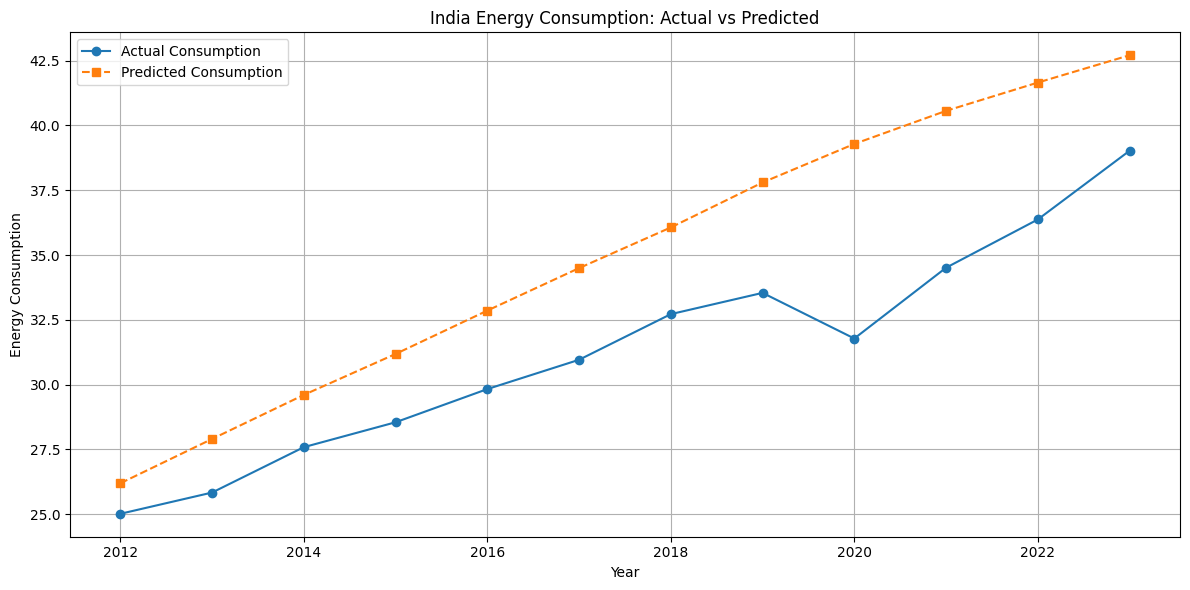

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    test_years,
    y_test_actual,
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    test_years,
    y_pred_actual,
    marker="s",
    linestyle="--",
    label="Predicted Consumption"
)

plt.title("India Energy Consumption: Actual vs Predicted")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:

print("Number of test years:", len(test_years))
print("Test years:", test_years)
print(results.tail())


Number of test years: 12
Test years: [2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023]
    Year  Actual Consumption  Predicted Consumption
7   2019           33.540001              37.796856
8   2020           31.780001              39.283314
9   2021           34.509998              40.559772
10  2022           36.369999              41.650295
11  2023           39.020000              42.703686
